In [1]:
# %pip install numpy pandas openpyxl matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
# %pip install "pyarrow<20"

Note: you may need to restart the kernel to use updated packages.


# setup

In [3]:
import hashlib, struct, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path(r"C:\Users\fiza\DAS_Datasets\data")   # our path
pd.set_option("display.width", 200, "display.max_columns", 50)

def size_str(n):
    for u in ("B", "kB", "MB", "GB"):
        if n < 1024 or u == "GB":
            return f"{n:.1f} {u}" if u != "B" else f"{n} B"
        n /= 1024

def file_hash(path, algo, chunk=1 << 20):
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()

def safe_zip(zf):
    for m in zf.namelist():
        if m.startswith(("/", "\\")) or ".." in Path(m).parts:
            raise ValueError(f"unsafe path in zip: {m}")

# Which files are present

In [4]:
expected = {
    "otway_metadata": ["das-metadata-v15.zip", "LICENSE", "README.md", "SHA256SUMS"],
    "otway_microseismic": ["DATA_DESCRIPTION.txt", "SEGY_trace_headers_outline.csv", "RAW_seismograms.zip"],
    "synthetic_das": ["synthetic_data.xlsx"],
}
rows = []
for folder, names in expected.items():
    for n in names:
        p = DATA / folder / n
        rows.append({"folder": folder, "file": n,
                     "status": "OK" if p.exists() else "MISSING",
                     "size": size_str(p.stat().st_size) if p.exists() else ""})
pd.DataFrame(rows)

,folder,file,status,size
0,otway_metadata,das-metadata-v15.zip,OK,34.2 kB
1,otway_metadata,LICENSE,OK,2.9 kB
2,otway_metadata,README.md,OK,1.6 kB
3,otway_metadata,SHA256SUMS,OK,237 B
4,otway_microseismic,DATA_DESCRIPTION.txt,OK,2.0 kB
5,otway_microseismic,SEGY_trace_headers_outline.csv,OK,13.8 kB
6,otway_microseismic,RAW_seismograms.zip,OK,700.1 MB
7,synthetic_das,synthetic_data.xlsx,OK,6.4 MB


# Otway metadata record

In [5]:
import sys
print(sys.executable)
import pyarrow
print(pyarrow.__version__)

C:\Miniconda3\envs\research\python.exe
19.0.1


In [6]:
d = DATA / "otway_metadata"
z = d / "das-metadata-v15.zip"

# checksum (SHA256SUMS mein zip ka hash hona chahiye)
for line in (d / "SHA256SUMS").read_text(errors="ignore").splitlines():
    parts = line.split()
    if len(parts) == 2 and parts[1].strip("*") == z.name:
        print("SHA256:", "MATCH" if file_hash(z, "sha256") == parts[0] else "MISMATCH")

out = d / "extracted"
out.mkdir(exist_ok=True)
with zipfile.ZipFile(z) as zf:
    safe_zip(zf)
    print("zip integrity:", "OK" if zf.testzip() is None else "BAD")
    zf.extractall(out)

meta = pd.read_parquet(next(out.rglob("das_metadata.parquet")))
print(meta.shape)
meta.T

SHA256: MATCH
zip integrity: OK
(6, 20)


,0,1,2,3,4,5
owd_well_key,AU:CO2CRC:CRC-3,AU:CO2CRC:CRC-4,AU:CO2CRC:CRC-5,AU:CO2CRC:CRC-6,AU:CO2CRC:CRC-7,ZZ:DASGAS:BOREHOLE
source_well_name,CRC-3,CRC-4,CRC-5,CRC-6,CRC-7,DASGAS borehole
source_well_id,CRC-3 (FFID 3 in the SEG-Y trace headers),CRC-4 (FFID 4 in the SEG-Y trace headers),CRC-5 (FFID 5 in the SEG-Y trace headers),CRC-6 (FFID 6 in the SEG-Y trace headers),CRC-7 (FFID 7 in the SEG-Y trace headers),not stated
fibre_type,not stated,not stated,not stated,not stated,not stated,not stated
cable_installation,not stated (the record says the data were «rec...,not stated (the record says the data were «rec...,not stated (the record says the data were «rec...,not stated (the record says the data were «rec...,not stated (the record says the data were «rec...,borehole fibre optic installation (record: «ac...
md_top,278.0,4.0,4.0,4.0,4.0,NaN
md_bottom,1645.0,1722.0,1767.0,1610.0,1644.0,NaN
channel_spacing,1.0,1.0,1.0,1.0,1.0,NaN
gauge_length,NaN,NaN,NaN,NaN,NaN,NaN
sampling_rate,1000.0,1000.0,1000.0,1000.0,1000.0,NaN


# well links

In [7]:
pd.read_parquet(next(out.rglob("well_links.parquet")))

,owd_well_key,source_well_name,linked_dataset,linked_well_name,match_method,match_note


# Otway description and header outline

In [8]:
p = DATA / "otway_microseismic" / "SEGY_trace_headers_outline.csv"
hdr_outline = pd.read_excel(p, engine="openpyxl")
print(hdr_outline.shape)
hdr_outline

(66, 5)


,Unnamed: 0,HEADER NAME,OFFSET in BYTES,VALUE,Comment
0,NaN,TRACENO,1,383,Trace sequence number within given well
1,NaN,NaN,5,0,NOT USED
2,NaN,FFID,9,7,WELL NAME as in CRC-#
3,NaN,CHAN,13,121,DAS channel number
4,NaN,SOURCE,17,0,NOT USED
...,...,...,...,...,...
61,NaN,HOUR,161,2,Hour of day
62,NaN,MINlJlc,163,29,Minute of hour
63,NaN,SECOND,165,0,Second of minute
64,NaN,NaN,167,3,"Timebasis{I -local, 2 • GMT, 3 • other)"


# synthetic dataset structure

In [9]:
xl = DATA / "synthetic_das" / "synthetic_data.xlsx"
sheets = pd.read_excel(xl, sheet_name=None, header=None)
print("sheets:", list(sheets))
for name, df in sheets.items():
    print(f"\nsheet '{name}': shape {df.shape}")
    display(df.iloc[:8, :10])

sheets: ['Sheet1']

sheet 'Sheet1': shape (1000, 1000)


,0,1,2,3,4,5,6,7,8,9
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# synthetic's numbers aur preview

numeric cells: 1000000 / 1000000  NaN: 0
numeric block shape: (1000, 1000)
min -0.9772  max 1  mean -0.0002585  std 0.1863


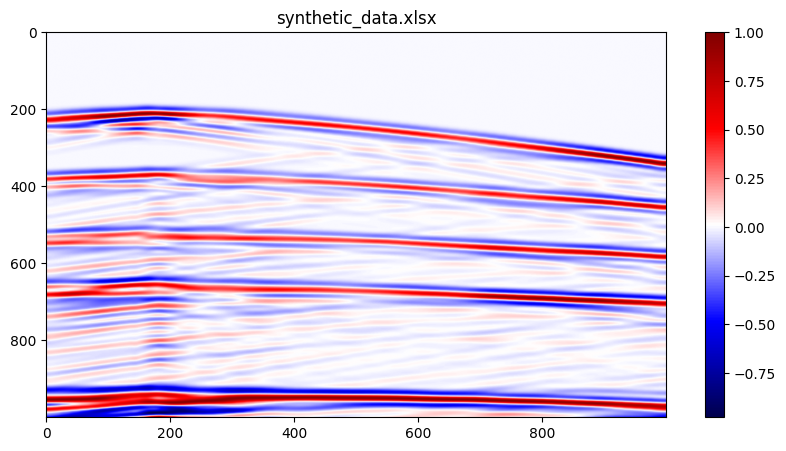

In [10]:
name = list(sheets)[0]                 # zaroorat ho to sheet ka naam badlein
raw = sheets[name]
num = raw.apply(pd.to_numeric, errors="coerce")
print("numeric cells:", int(num.notna().sum().sum()), "/", raw.size, " NaN:", int(num.isna().sum().sum()))
arr = num.dropna(how="all").dropna(axis=1, how="all").to_numpy(float)
print("numeric block shape:", arr.shape)
print(f"min {np.nanmin(arr):.4g}  max {np.nanmax(arr):.4g}  mean {np.nanmean(arr):.4g}  std {np.nanstd(arr):.4g}")

plt.figure(figsize=(10, 5))
plt.imshow(arr, aspect="auto", cmap="seismic")
plt.colorbar(); plt.title("synthetic_data.xlsx"); plt.show()

# In synthetic file time aur channel axis

first non-zero row: 128
zero rows: 128  zero cols: 0


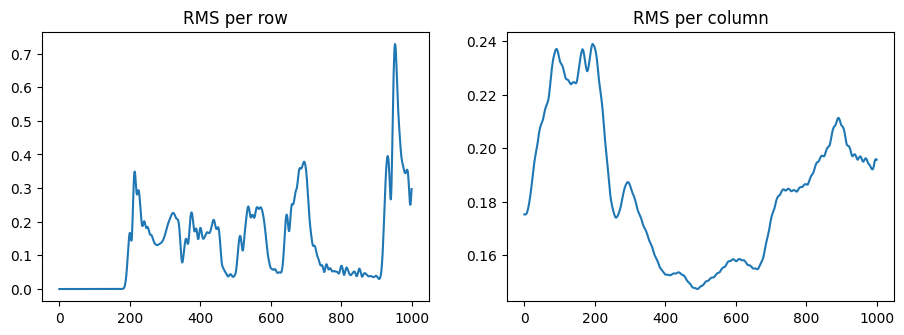

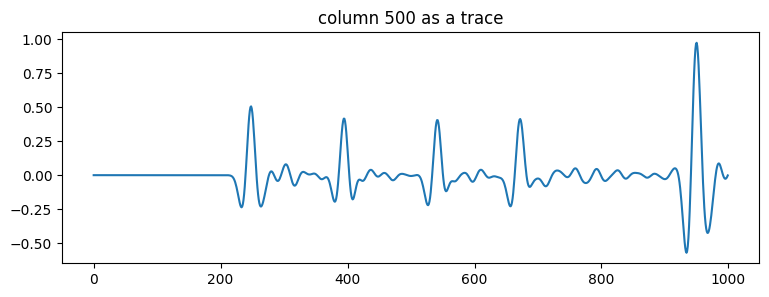

In [11]:
S = arr
row_e = np.sqrt((S**2).mean(axis=1)); col_e = np.sqrt((S**2).mean(axis=0))
print("first non-zero row:", int(np.argmax(row_e > 1e-6)))
print("zero rows:", int((row_e < 1e-6).sum()), " zero cols:", int((col_e < 1e-6).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(row_e); ax[0].set_title("RMS per row")
ax[1].plot(col_e); ax[1].set_title("RMS per column")
plt.show()

plt.figure(figsize=(9, 3)); plt.plot(S[:, 500]); plt.title("column 500 as a trace"); plt.show()

# Full list of SEG-Y headers (confirmation of the depth byte)

In [12]:
print(hdr_outline.iloc[:, 1:].to_string())

       HEADER NAME OFFSET in BYTES    VALUE                                                 Comment
0          TRACENO               1      383                 Trace sequence number within given well
1              NaN               5        0                                                NOT USED
2             FFID               9        7                                   WELL NAME as in CRC-#
3             CHAN              13      121                                      DAS channel number
4           SOURCE              17        0                                                NOT USED
5              CDP              21        0                                                NOT USED
6            SEQNO              25        0                                                NOT USED
7              NaN             NaN      NaN                                                NOT USED
8         TRC_TYPE              29        0                                                NOT USED


# Otway raw zip

In [13]:
RAW = DATA / "otway_microseismic" / "RAW_seismograms.zip"
EXPECTED_MD5 = "7df5b37bc5e839749bb9e082047a18db"

if not RAW.exists():
    print("RAW_seismograms.zip is not yet found, ru this cell later")
else:
    print("size:", size_str(RAW.stat().st_size), "(Whole file ~734 MB should be there)")
    if RAW.stat().st_size > 730_000_000:
        md5 = file_hash(RAW, "md5")
        print("MD5:", md5, "MATCH" if md5 == EXPECTED_MD5 else "MISMATCH, again download it")
    else:
        print("File is incomplete, don't proceed forward")

size: 700.1 MB (Whole file ~734 MB should be there)
MD5: 7df5b37bc5e839749bb9e082047a18db MATCH


# functions for reading SEG-Y 

In [14]:
NP_FMT = {2: ">i4", 3: ">i2", 5: ">f4", 8: ">i1"}

def segy_binary_header(buf):
    dt_us, = struct.unpack(">H", buf[3216:3218])
    ns, = struct.unpack(">H", buf[3220:3222])
    fmt, = struct.unpack(">H", buf[3224:3226])
    return dt_us, ns, fmt

def ibm2ieee(a):
    a = a.astype(np.uint32)
    sign = np.where((a >> 31) & 1, -1.0, 1.0)
    exp = ((a >> 24) & 0x7F).astype(np.int32)
    frac = (a & 0xFFFFFF) / float(1 << 24)
    return (sign * frac * 16.0 ** (exp - 64)).astype(np.float32)

def read_segy(buf):
    dt_us, ns, fmt = segy_binary_header(buf)
    bps = 4 if fmt in (1, 2, 5) else 2 if fmt == 3 else 1
    tb = 240 + ns * bps
    n = (len(buf) - 3600) // tb
    raw = np.frombuffer(buf, dtype=np.uint8, count=n * tb, offset=3600).reshape(n, tb)
    hdr = raw[:, :240]
    body = np.ascontiguousarray(raw[:, 240:])
    arr = ibm2ieee(body.view(">u4")) if fmt == 1 else body.view(NP_FMT[fmt]).astype(np.float32)
    return dt_us, ns, fmt, n, hdr, arr

In [15]:
zf = zipfile.ZipFile(RAW); safe_zip(zf)
sgy = [n for n in zf.namelist() if n.lower().endswith((".sgy", ".segy"))]
print(len(zf.namelist()), "entries;", len(sgy), "segy files")
print(sgy[:5] if sgy else zf.namelist()[:5])

162 entries; 160 segy files
['RAW_seismograms/event_2_6_strain_geom.sgy', '__MACOSX/RAW_seismograms/._event_2_6_strain_geom.sgy', 'RAW_seismograms/event_11_6_strain_geom.sgy', '__MACOSX/RAW_seismograms/._event_11_6_strain_geom.sgy', 'RAW_seismograms/event_18_3_strain_geom.sgy']


In [17]:
sgy = [n for n in zf.namelist() if n.lower().endswith((".sgy", ".segy")) and not n.startswith("__MACOSX") and "/._" not in n]
print(len(sgy))   # 80 aana chahiye (5 wells x 16 files)

80


# Detail view of one event

RAW_seismograms/event_2_6_strain_geom.sgy
channels 1571, samples 5000, fs 1000 Hz, duration 5.00 s, format 5
channel depth 4..1610 m, median step 1.0 m
amplitude min -2.74e+03 max 2.42e+03 std 19
NaN/Inf: 0  all-zero channels: 0


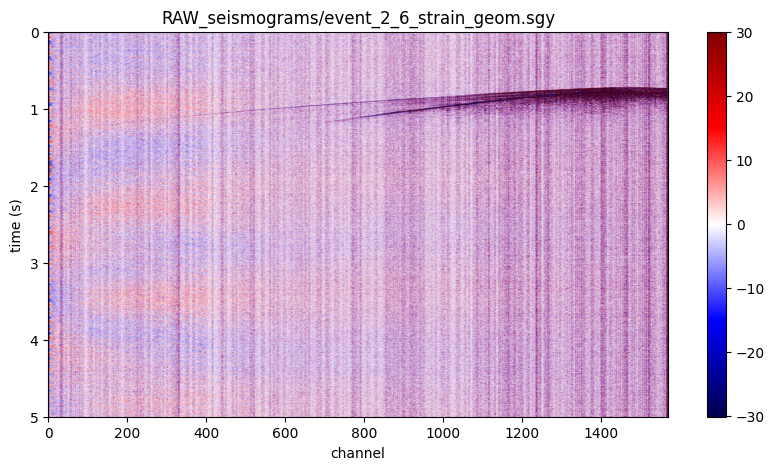

In [16]:
name = sgy[0]                          # koi bhi file chun sakti hain
dt, ns, fmt, ntr, hdr, arr = read_segy(zf.read(name))
fs = 1e6 / dt
md = np.frombuffer(np.ascontiguousarray(hdr[:, 48:52]).tobytes(), dtype=">i4")

print(name)
print(f"channels {ntr}, samples {ns}, fs {fs:.0f} Hz, duration {ns/fs:.2f} s, format {fmt}")
print(f"channel depth {md.min()}..{md.max()} m, median step {np.median(np.diff(md)):.1f} m")
print(f"amplitude min {arr.min():.3g} max {arr.max():.3g} std {arr.std():.3g}")
print("NaN/Inf:", int((~np.isfinite(arr)).sum()), " all-zero channels:", int((np.abs(arr).max(axis=1) == 0).sum()))

clip = np.percentile(np.abs(arr), 99)
plt.figure(figsize=(10, 5))
plt.imshow(arr.T, aspect="auto", cmap="seismic", vmin=-clip, vmax=clip, extent=[0, ntr, ns / fs, 0])
plt.xlabel("channel"); plt.ylabel("time (s)"); plt.title(name); plt.colorbar(); plt.show()